In [28]:
import numpy as np
from scipy.special import erf
from scipy.optimize import curve_fit

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import MultipleLocator, NullFormatter



In [29]:
# Load default mpl style
plt.style.use("assets/TRPES.mplstyle")

#Other standard figure widths
fwid = 6.26894
ACSwid = 3.33
thesisWid = 14/2.54

#Default mpl colour tablet
colors = list(mcolors.TABLEAU_COLORS)

#Extra colours
violet = '#5D3FD3'
red = '#D62828'

blue ='#3A86FF'
green='#6A994E'

In [19]:
def _monoexp(t,k,sigma):
    """Monoexponential helper function"""

    return 0.5*np.exp(-k*t + 0.5*(k**2)*(sigma**2)) * (1 + erf((t-k*sigma**2)/(sigma*np.sqrt(2))))


class EAS_model():
    """A -> B -> C"""
    def __init__(self,t0,sigma,delays_length,energy_length):
        #time-zero
        self.t0 = t0
        # sigma = cross-correlation / 2.335
        self.sigma = sigma
        #Number of delays
        self.points_per_trace = delays_length
        # Number of energy values
        self.traces_number = energy_length


    @staticmethod
    def B_model(t,A2,tau1,tau2,sigma):
        """Concentration of [B] as a function of time. Convoluted with Gaussian"""
        k1, k2 = 1/tau1, 1/tau2
        return A2*(k1/(k2-k1))*(_monoexp(t,k1,sigma) - _monoexp(t,k2,sigma))

    @staticmethod
    def A_model(t,A1,tau1,sigma):
        k1 = 1/tau1
        return A1*_monoexp(t,k1,sigma)

    def kinetic_model_gau(self,x,A1,A2,tau1,tau2,
                          t0 = None,sigma = None):
        if t0 == None:
            t0 = self.t0
        if sigma == None:
            sigma = self.sigma

        return self.A_model(x-t0,A1,tau1,sigma) + self.B_model(x-t0,A2,tau1,tau2,sigma)



    def global_fit(self,flat_delays, tau1, tau2, *amplitudes):


        delays = flat_delays.reshape(self.traces_number, self.points_per_trace)
        amps = np.array(amplitudes).reshape(self.traces_number, 2)  

        return self.kinetic_model_gau(
            delays,
            amps[:, 0][:, None], 
            amps[:, 1][:, None],
            tau1, tau2,
        ).ravel()


In [20]:
CROSS_CORRELATION = 0.320 #cross-correlation with 250 & 267
SIGMA = CROSS_CORRELATION / 2.355 



In [21]:
loaddata = np.loadtxt("data/out/subtractedspectra.csv",delimiter=',')

In [22]:
energies_rebinned = loaddata[0,1:]
delays_t0 = loaddata[1:,0]
subtracted_rebinned = loaddata [1:,1:]

In [23]:
#Mask traces
mask = energies_rebinned<2.2
traces = subtracted_rebinned[:,mask]
traces.shape

(47, 70)

In [24]:
# Normalise traces
#Total counts
trace = -np.trapezoid(subtracted_rebinned,axis=1,x=energies_rebinned)
traces /= max(trace)

In [25]:
#Flatten delays
delays = delays_t0
# Tile delays
flat_delays = np.tile(delays,(traces.shape[1]))
#Flatten traces
flat_traces = traces.T.flatten() 
flat_traces.shape,flat_delays.shape

((3290,), (3290,))

In [26]:
model = EAS_model(0,SIGMA,*traces.shape)

In [27]:
p0 = [1,3.5]+[x for n in range(70) for x in (2*n, n)]

params,pcov = curve_fit(model.global_fit,flat_delays,flat_traces,
                        p0 = p0,bounds=(-np.inf,np.inf),)
perr = np.sqrt(np.diag(pcov))
params[:2],params[2:]

(array([0.54994701, 2.84328417]),
 array([ 1.59187910e-02, -5.87489608e-04,  1.56286053e-02, -2.39793895e-04,
         1.90217410e-02,  1.99860584e-03,  2.27903191e-02, -4.20829289e-04,
         2.10729305e-02,  3.05283440e-03,  2.87973018e-02,  4.12545384e-03,
         3.84547402e-02,  4.91153443e-03,  4.60567356e-02,  2.85401304e-03,
         6.21095380e-02,  6.36141728e-03,  7.64091009e-02,  1.62730063e-02,
         1.02820899e-01,  1.88643788e-02,  1.29392627e-01,  2.70571883e-02,
         1.59954236e-01,  3.21418639e-02,  2.07340557e-01,  5.42566306e-02,
         2.56452239e-01,  7.05399814e-02,  3.01083671e-01,  9.10440368e-02,
         3.48860727e-01,  1.16282896e-01,  4.05568938e-01,  1.58477221e-01,
         4.66195811e-01,  1.92471693e-01,  5.25669224e-01,  2.25041460e-01,
         6.06629004e-01,  2.47941061e-01,  6.59976847e-01,  3.13449076e-01,
         7.06978508e-01,  3.75863550e-01,  7.82961532e-01,  4.40067598e-01,
         8.64824546e-01,  4.63001312e-01,  9.23674838e

0.5499470051915128 2.8432841704894796


(-1.0, 5.0)

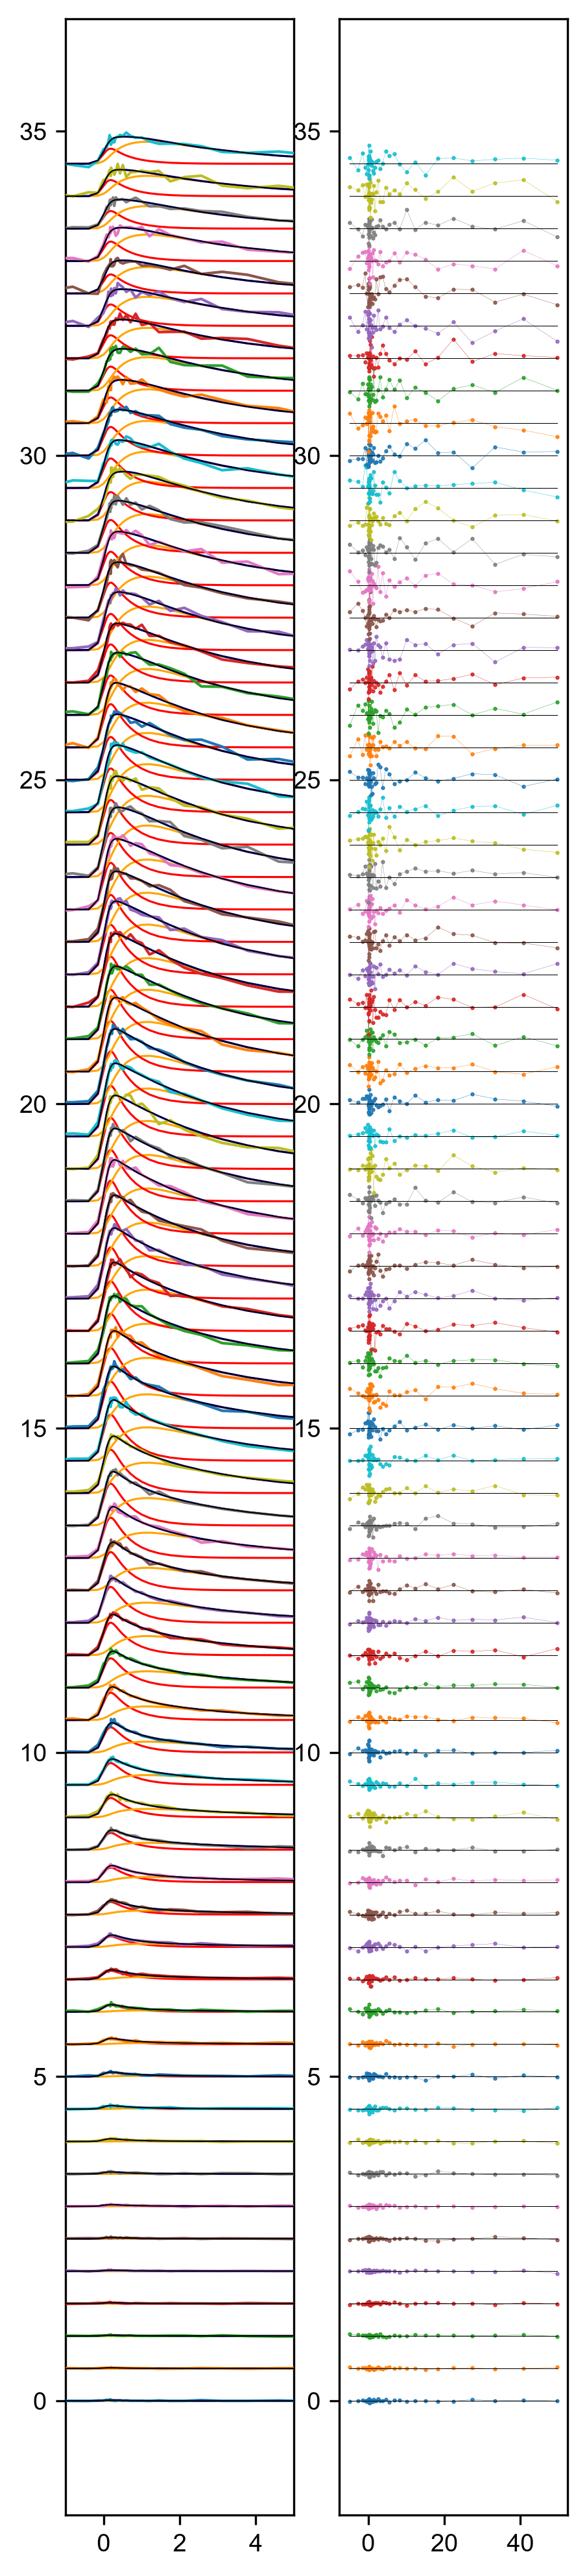

In [30]:
fig, (ax0,ax1) = plt.subplots(1,2)
# params=p0
tau1,tau2, amplitudes = params[0],params[1],params[2:]
tau1_err,tau2_err, amplitudes_err = perr[0],perr[1],perr[2:]
print(tau1,tau2)
sigma = 0.320 / 2.355 #cross-correlation with 250 & 267
t0 = 0

for n in range(70):
    
    ax0.plot(delays,traces[:,n]+.5*n,zorder=20)
    
    trace = model.kinetic_model_gau(delays,amplitudes[2*n],amplitudes[2*n+1],tau1,tau2)
    ax0.plot(delays,trace+.5*n,'k',zorder=30,lw=.5)
    
    
    trace =  model.A_model(delays,amplitudes[2*n],tau1,sigma)
    ax0.plot(delays,trace+.5*n,'r',lw=.75)
    
    trace =  model.B_model(delays,amplitudes[2*n+1],tau1,tau2,sigma)
    ax0.plot(delays,trace+.5*n,'orange',lw=.75)
    ax0.plot(delays,model.A_model(delays,amplitudes[2*n],tau1,sigma)+trace+.5*n,'b',lw=.75)

    # Residuals
    trace = model.kinetic_model_gau(delays,amplitudes[2*n],amplitudes[2*n+1],tau1,tau2)
    ax1.plot(delays,3*(traces[:,n]-trace)+.5*n,'o-',zorder=20,ms=.5,lw=.1)
    ax1.plot(delays,delays*0+.5*n,'k',zorder=30,lw=.25)
    
ax1.set_ylim(ax0.get_ylim())
plt.gcf().set_size_inches(ACSwid,ACSwid*5)

ax0.set_xlim(-1,5)

Text(0, 0.5, 'Photoelectron signal / a.u.')

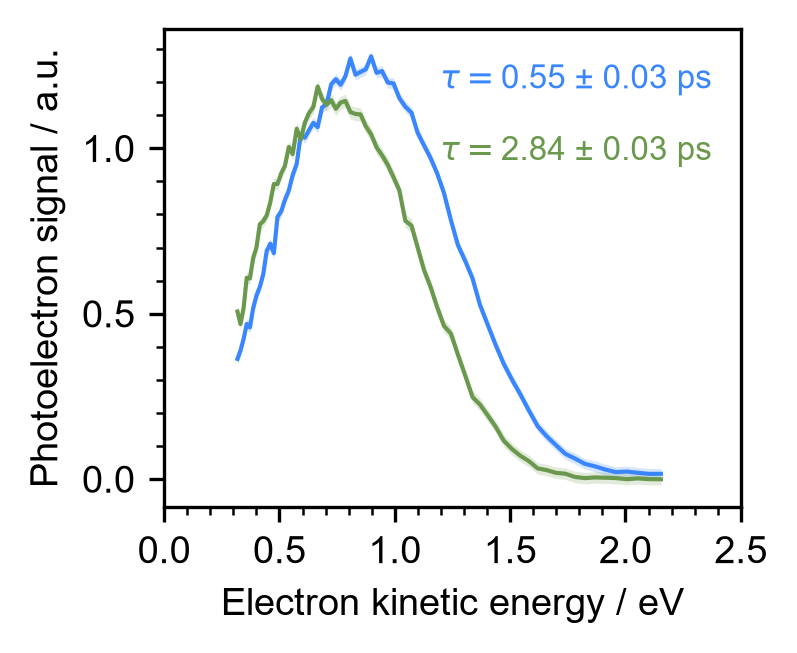

In [32]:
fig,ax = plt.subplots(1)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(300)
fig.set_size_inches(thesisWid*.45,thesisWid/2*0.75)

A1s = amplitudes[0::2]
A2s = amplitudes[1::2]
A1s_err = amplitudes_err[0::2]
A2s_err = amplitudes_err[1::2]
energies = energies_rebinned[mask]

ax.plot(energies,A1s,'-',c=blue,ms=1,label=f"$\\tau = ${tau1:.2f}$\\pm${tau1_err:.2f} ps")
ax.plot(energies,A2s,'-',c=green,ms=1,label=f"$\\tau = ${tau2:.2f}$\\pm${tau2_err:.2f} ps")

ax.fill_between(energies,A1s-A1s_err,A1s+A1s_err,alpha=.2,color=blue,lw=0)
ax.fill_between(energies,A2s-A2s_err,A2s+A2s_err,alpha=.2,color=green,lw=0)

ax.text(.95,.8,f"$\\tau =${tau1:.2f} ± {tau1_err:.2f} ps\n",ha='right',c=blue,fontsize=8,transform=ax.transAxes)
ax.text(.95,.65,f"$\\tau =${tau2:.2f} ± {tau2_err:.2f} ps\n",ha='right',c=green,fontsize=8,transform=ax.transAxes)

# ax.legend(frameon=False, title='EAS',title_fontsize=8)
ax = plt.gca()
ax.set_xlim(0,2.5)
# ax.set_ylim(0,1.2)
ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax.yaxis.set_major_locator(MultipleLocator(.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.1))
    
ax.set_xlabel("Electron kinetic energy / eV",)
ax.set_ylabel("Photoelectron signal / a.u.")
